# Three-Layer Recurring Tasks with a Shared Top

**Questions:** when two recurring tasks share their upper layers but differ in their first layer, (1) can a three-layer learner learn them, (2) does it keep the shared upper layers fixed while relearning the task-specific bottom at each switch, and (3) does recovery after a task returns depend on how long it was absent?

**Teacher.** 21 independent ±1 inputs. Each task has its own five first-layer LTUs, each firing when its ±1-weighted input sum exceeds 2, about a third of the time. Both tasks share the rest: five second-layer LTUs reading the task's first layer, five third-layer LTUs reading the second, all with ±1 weights and thresholded to fire about 30% of the time, and ±1 weights to ten linear outputs. No task ID is given. Targets have Gaussian noise with standard deviation 1, so the RMSE floor is 1.

The two tasks' second-layer units are different functions of the input, so a learner without a task ID cannot hold both: holding both tasks needs 10 → 10 → 5 units, while 10 → 5 → 5 suffices if the weights into layer 2 are relearned at every switch. The weights into layer 3 and the output weights can then stay fixed.

**Learner.** 21 inputs → 45 → 24 → 24 standardized LTUs → 10 linear outputs, 4.5 times 10 → 5 → 5. Standardization, its custom backward and the sigmoid surrogate derivative are as in 02.

**Methods.**
- **SGD:** fan-in initialization, zero readout, one step size for every layer. Sweep 2⁻¹⁰ … 2⁻⁴.
- **Unstandardized SGD:** as SGD, but hidden units pass their raw 0/1 firing forward, without standardization. Its own step-size sweep.
- **Autostep:** `squared_inputs`, meta step 0.02, initial step 2⁻⁸, hidden weights uniform ±2⁻⁸, zero readout.
- **Baselines:** the teacher's weights into layer 3 and its output weights, given and frozen. Only the bottom learns: 45 standardized first-layer LTUs and five binary second-layer LTUs feeding the frozen top, initialized like the method. One baseline per method: SGD with the step size chosen from the SGD sweep, and Autostep with the settings above.

**Schedule.** Train for 1.5M steps, switching tasks every 10k steps, starting with task 0 and ending with task 1. Then branch three copies of every learner: each trains on task 0 alone for 50k, 100k or 500k steps, then on task 1 for 10k steps and on task 0 for 10k steps. Every method and branch sees the same inputs and noise for a given seed. Five seeds.

Curves show online RMSE, averaged over 1k-step windows, then over seeds; the first point is step 1.

In [1]:
from functools import partial
from time import perf_counter
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

# Problem
N_INPUTS, WIDTH, N_OUTPUTS, N_TASKS = 21, 5, 10, 2
NOISE = 1.

# Learner
WIDTHS = (45, 24, 24)
BASELINE_WIDTH = WIDTHS[0]  # first layer of the baselines; their second layer has WIDTH units
EMA_RATE, VAR_FLOOR = 1e-3, .01
INIT_RATE, META_RATE = 2**-8, .02  # Autostep
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True, tau=1e4, version='squared_inputs')
SGD_EXPONENTS = tuple(range(-10, -3))

# Schedule
PERIOD, ACQUISITION, WINDOW = 10_000, 1_500_000, 1000
ABSENCES = (50_000, 100_000, 500_000)
N_SEEDS = 5

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

## Task

In [2]:
CALIBRATION = jax.random.rademacher(jax.random.PRNGKey(0), (10_000, N_INPUTS), dtype=jnp.float32)


def thresholds(sums):
    """Per unit (row), the half-integer threshold that makes it fire closest to 30% of the time."""
    candidates = jnp.arange(-WIDTH, WIDTH) + .5
    return candidates[jnp.abs((sums[..., None] > candidates).mean(-2) - .3).argmin(-1)]


def init_teacher(key):
    lower_key, middle_key, top_key, out_key = jax.random.split(key, 4)
    lower = jax.random.rademacher(lower_key, (N_TASKS, WIDTH, N_INPUTS), dtype=jnp.float32)
    middle = jax.random.rademacher(middle_key, (WIDTH, WIDTH), dtype=jnp.float32)
    top = jax.random.rademacher(top_key, (WIDTH, WIDTH), dtype=jnp.float32)
    out = jax.random.rademacher(out_key, (N_OUTPUTS, WIDTH), dtype=jnp.float32)
    # Calibrate the shared layers on both tasks' first-layer features.
    first = (jnp.einsum('tui,ni->utn', lower, CALIBRATION) > 2).reshape(WIDTH, -1).astype(jnp.float32)
    middle_sums = middle @ first
    middle_thresholds = thresholds(middle_sums)
    top_sums = top @ (middle_sums > middle_thresholds[:, None]).astype(jnp.float32)
    return lower, middle, middle_thresholds, top, thresholds(top_sums), out


def teacher_layers(teacher, task, x):
    lower, middle, middle_thresholds, top, top_thresholds, _ = teacher
    first = (lower[task] @ x > 2).astype(jnp.float32)
    second = (middle @ first > middle_thresholds).astype(jnp.float32)
    return first, second, (top @ second > top_thresholds).astype(jnp.float32)


def target(teacher, task, x):
    return teacher[-1] @ teacher_layers(teacher, task, x)[2]


def frozen_top(teacher, z):
    """The teacher's weights into layer 3 and its output weights, applied to second-layer pre-activations z."""
    _, _, _, top, top_thresholds, out = teacher
    return out @ ltu(top @ ltu(z) - top_thresholds)

## Learners

As in 02: for h = (b − μ) / σ, the custom backward of `standardize` sends (g − E[g] − h E[g h]) / σ to the unit's own weights and earlier layers, using running means of g and g h. A baseline is the same network with one standardized hidden layer, whose last weight matrix produces second-layer pre-activations that pass through the frozen top instead of a readout.

In [3]:
@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Learner(NamedTuple):
    weights: tuple  # hidden layers, then the last layer; the last column holds the bias
    means: tuple    # running firing rate of each hidden unit
    traces: tuple   # per hidden layer: running means of the arriving error g and of g * h
    opt: object     # Autostep state; None for SGD


def init_learner(key, autostep, widths=WIDTHS, outputs=N_OUTPUTS, zero_last=True):
    sizes, weights, fan_in = (*widths, outputs), [], N_INPUTS
    for i, (width, subkey) in enumerate(zip(sizes, jax.random.split(key, len(sizes)))):
        bound = INIT_RATE if autostep else np.sqrt(3 / fan_in)
        w = jax.random.uniform(subkey, (width, fan_in + 1), minval=-bound, maxval=bound).at[:, -1].set(0.)
        weights.append(jnp.zeros_like(w) if zero_last and i == len(widths) else w)
        fan_in = width
    weights = tuple(weights)
    return Learner(weights, tuple(jnp.full(w, .5) for w in widths),
                   tuple((jnp.zeros(w), jnp.zeros(w)) for w in widths),
                   OPTIMIZER.init(weights) if autostep else None)


def init_baseline(key, autostep):
    return init_learner(key, autostep, (BASELINE_WIDTH,), WIDTH, zero_last=False)


def backprop(weights, means, traces, x, y, rate, head=None, standardized=True):
    """Prediction and gradients for one example. Firing rates first move toward this example's bits by `rate`.
    `head`, if given, maps the last layer's output to the prediction. Unstandardized units pass their raw bits."""
    def loss(weights, probes):
        a, sources, hs, new_means = x, [], [], []
        for w, mean, (error_mean, error_h_mean), probe in zip(weights[:-1], means, traces, probes):
            source = jnp.append(a, 1.)
            bits = ltu(w @ source)
            mean = mean + rate * (jax.lax.stop_gradient(bits) - mean)
            h = standardize(bits, mean, error_mean, error_h_mean) if standardized else bits
            a = h + probe  # the probe is zero; its gradient is the error g arriving at h
            sources.append(source); hs.append(h); new_means.append(mean)
        sources.append(jnp.append(a, 1.))
        prediction = weights[-1] @ sources[-1]
        prediction = prediction if head is None else head(prediction)
        return .5 * jnp.sum((prediction - y) ** 2), (prediction, sources, hs, tuple(new_means))
    probes = tuple(jnp.zeros(w.shape[0]) for w in weights[:-1])
    (grads, errors), (prediction, sources, hs, new_means) = jax.grad(loss, (0, 1), has_aux=True)(weights, probes)
    return prediction, grads, errors, sources, hs, new_means


def learn(learner, x, y, head=None, standardized=True):
    prediction, grads, errors, sources, hs, means = backprop(*learner[:3], x, y, EMA_RATE, head, standardized)
    traces = tuple((m + EMA_RATE * (g - m), mh + EMA_RATE * (g * h - mh))
                   for (m, mh), g, h in zip(learner.traces, errors, hs))
    return learner._replace(means=means, traces=traces), prediction, grads, sources


def sgd_step(state, x, y, teacher, head=None, standardized=True):
    learner, rate = state
    learner, prediction, grads, _ = learn(learner, x, y, head, standardized)
    weights = tuple(w - rate * g for w, g in zip(learner.weights, grads))
    return (learner._replace(weights=weights), rate), jnp.mean((prediction - y) ** 2)


def autostep_step(learner, x, y, teacher, head=None):
    learner, prediction, grads, sources = learn(learner, x, y, head)
    updates, opt = OPTIMIZER.update((grads, None, tuple(s[None] for s in sources)), learner.opt, learner.weights)
    return learner._replace(weights=jax.tree.map(jnp.add, learner.weights, updates), opt=opt), jnp.mean((prediction - y) ** 2)


def sgd_baseline_step(state, x, y, teacher):
    return sgd_step(state, x, y, teacher, partial(frozen_top, teacher))


def autostep_baseline_step(state, x, y, teacher):
    return autostep_step(state, x, y, teacher, partial(frozen_top, teacher))

**Backward check.** As in 02: with exact batch statistics on 4,096 fixed inputs, compare the custom backward with automatic differentiation through the batch mean and variance, for five random three-layer networks at full float32 matmul precision.

In [4]:
def check_backward(key):
    weight_key, readout_key, x_key, y_key = jax.random.split(key, 4)
    weights = init_learner(weight_key, autostep=False).weights
    weights = (*weights[:-1], jax.random.normal(readout_key, weights[-1].shape))
    x = jax.random.rademacher(x_key, (4096, N_INPUTS), dtype=jnp.float32)
    y = jax.random.normal(y_key, (4096, N_OUTPUTS))
    ones = jnp.ones((len(x), 1))

    def exact_loss(weights):
        a, means = x, []
        for w in weights[:-1]:
            bits = ltu(jnp.concatenate([a, ones], 1) @ w.T)
            mean = bits.mean(0)
            a = (bits - mean) / jnp.sqrt(jnp.maximum(((bits - mean) ** 2).mean(0), VAR_FLOOR))
            means.append(jax.lax.stop_gradient(mean))
        prediction = jnp.concatenate([a, ones], 1) @ weights[-1].T
        return .5 * jnp.mean(jnp.sum((prediction - y) ** 2, 1)), tuple(means)

    exact, means = jax.grad(exact_loss, has_aux=True)(weights)
    per_example = jax.vmap(backprop, in_axes=(None, None, None, 0, 0, None))
    traces = tuple((jnp.zeros(w), jnp.zeros(w)) for w in WIDTHS)
    for _ in WIDTHS:  # each pass makes one more layer's error statistics exact, from the top down
        _, _, errors, _, hs, _ = per_example(weights, means, traces, x, y, 0.)
        traces = tuple((g.mean(0), (g * h).mean(0)) for g, h in zip(errors, hs))
    custom = jax.tree.map(lambda g: g.mean(0), per_example(weights, means, traces, x, y, 0.)[1])
    return jnp.stack([jnp.abs(a - b).max() / jnp.abs(a).max() for a, b in zip(exact, custom)])


with jax.default_matmul_precision('highest'):
    differences = np.asarray(jax.jit(jax.vmap(check_backward))(jax.random.split(jax.random.PRNGKey(1), 5)))
print('Largest difference from the exact gradient, relative to its largest entry, per weight matrix:', differences.max(0))
assert differences.max() < 1e-5

Largest difference from the exact gradient, relative to its largest entry, per weight matrix: [3.2259370e-06 2.9010776e-06 3.0891711e-06 2.8580557e-06]


## Experiment

In [5]:
def run(step, state, key, teacher, tasks):
    """Train on tasks[i] throughout window i. Returns online MSE per window and of the first example."""
    def window(carry, task):
        def sample(carry, _):
            state, key = carry
            key, x_key, noise_key = jax.random.split(key, 3)
            x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
            y = target(teacher, task, x) + NOISE * jax.random.normal(noise_key, (N_OUTPUTS,))
            state, squared_error = step(state, x, y, teacher)
            return (state, key), squared_error
        carry, squared_error = jax.lax.scan(sample, carry, None, length=WINDOW)
        return carry, (squared_error.mean(0), squared_error[0])
    (state, key), (mse, first) = jax.lax.scan(window, (state, key), tasks)
    return state, key, mse, first[0]


ACQUISITION_TASKS = np.arange(ACQUISITION // WINDOW) * WINDOW // PERIOD % 2
BRANCH_TASKS = [np.repeat([0, 1, 0], np.array([absence, PERIOD, PERIOD]) // WINDOW) for absence in ABSENCES]


def run_all(step, states, keys, teachers):
    """Acquisition, then every branch from the acquired state. One RMSE curve per absence, shape (lane, step-1 + windows, ...)."""
    started = perf_counter()
    simulate = jax.jit(jax.vmap(partial(run, step), in_axes=(0, 0, 0, None)))
    states, keys, mse, first = simulate(states, keys, teachers, ACQUISITION_TASKS)
    curves = [np.sqrt(np.concatenate([first[:, None], mse, simulate(states, keys, teachers, tasks)[2]], 1))
              for tasks in BRANCH_TASKS]
    print(f'Runtime: {perf_counter() - started:.1f}s')
    return curves


teacher_keys, learner_keys, data_keys = jax.random.split(jax.random.PRNGKey(0), (3, N_SEEDS))
teachers = jax.vmap(init_teacher)(teacher_keys)


CONTEXT = 100_000  # steps shown on each side of a cut


def plot_runs(panels, labels, colors, title):
    fig = plt.figure(figsize=(12, 3 * len(ABSENCES) + .4), layout='constrained')
    rows = fig.subfigures(len(ABSENCES) + 1, 1, height_ratios=[1] * len(ABSENCES) + [.12])  # last row: legend
    mark = dict(marker=[(-1, -1), (1, 1)], markersize=8, linestyle='none', color='black', mew=1, clip_on=False)
    for row, absence, panel in zip(rows, ABSENCES, panels):
        steps = np.concatenate([[1], np.arange(1, panel.shape[-1]) * WINDOW])
        # Show the first and last CONTEXT steps of acquisition, and of the absence when it is longer than 2 * CONTEXT.
        edges = [0, CONTEXT, ACQUISITION - CONTEXT]
        if absence > 2 * CONTEXT:
            edges += [ACQUISITION + CONTEXT, ACQUISITION + absence - CONTEXT]
        spans = list(zip(edges[::2], edges[1::2] + [steps[-1]]))
        axes = row.subplots(1, len(spans), sharey=True, width_ratios=[right - left for left, right in spans])  # same x scale
        for i, (ax, (left, right)) in enumerate(zip(axes, spans)):
            visible = (steps >= left) & (steps <= right)
            for values, label, color in zip(panel, labels, colors):
                ax.plot(steps[visible], values.mean(0)[visible], label=label, color=color, lw=.8)
            ax.axhline(1., color='black', ls=':', label='Noise floor')
            ax.set(xlim=(left, right), ylim=(.95, 2.))  # diverging step sizes leave the plot
            ax.locator_params(axis='x', nbins=4)
            ax.xaxis.set_major_formatter(lambda v, _: f'{v / 1e6:g}M' if v else '0')
            ax.grid(True, alpha=.3)
            for side in [0] * (i > 0) + [1] * (i < len(spans) - 1):  # hide the spine and mark each cut
                ax.spines['right' if side else 'left'].set_visible(False)
                ax.plot([side, side], [0, 1], transform=ax.transAxes, **mark)
            if i > 0:
                ax.tick_params(axis='y', left=False)
        axes[0].set_ylabel('RMSE')
        row.suptitle(f'Task 1 absent for {absence // 1000}k steps', fontsize=10)
    rows[-2].supxlabel('Steps', fontsize=10)
    rows[-1].legend(*axes[0].get_legend_handles_labels(), loc='center', ncol=len(labels) + 1, fontsize=8)
    fig.suptitle(title)
    plt.show()

## SGD step sizes

Every step size, five seeds, for SGD and for unstandardized SGD. The comparison below uses, for each, the step size with the lowest RMSE over the final 20k steps (both returns), averaged over the three absence lengths.

Runtime: 48.9s
SGD final-20k RMSE: 2^-10: 1.067, 2^-9: 1.040, 2^-8: 1.046, 2^-7: 1.074, 2^-6: 1.138, 2^-5: 270730.250, 2^-4: 2766118.250
SGD chosen step size: 2^-9


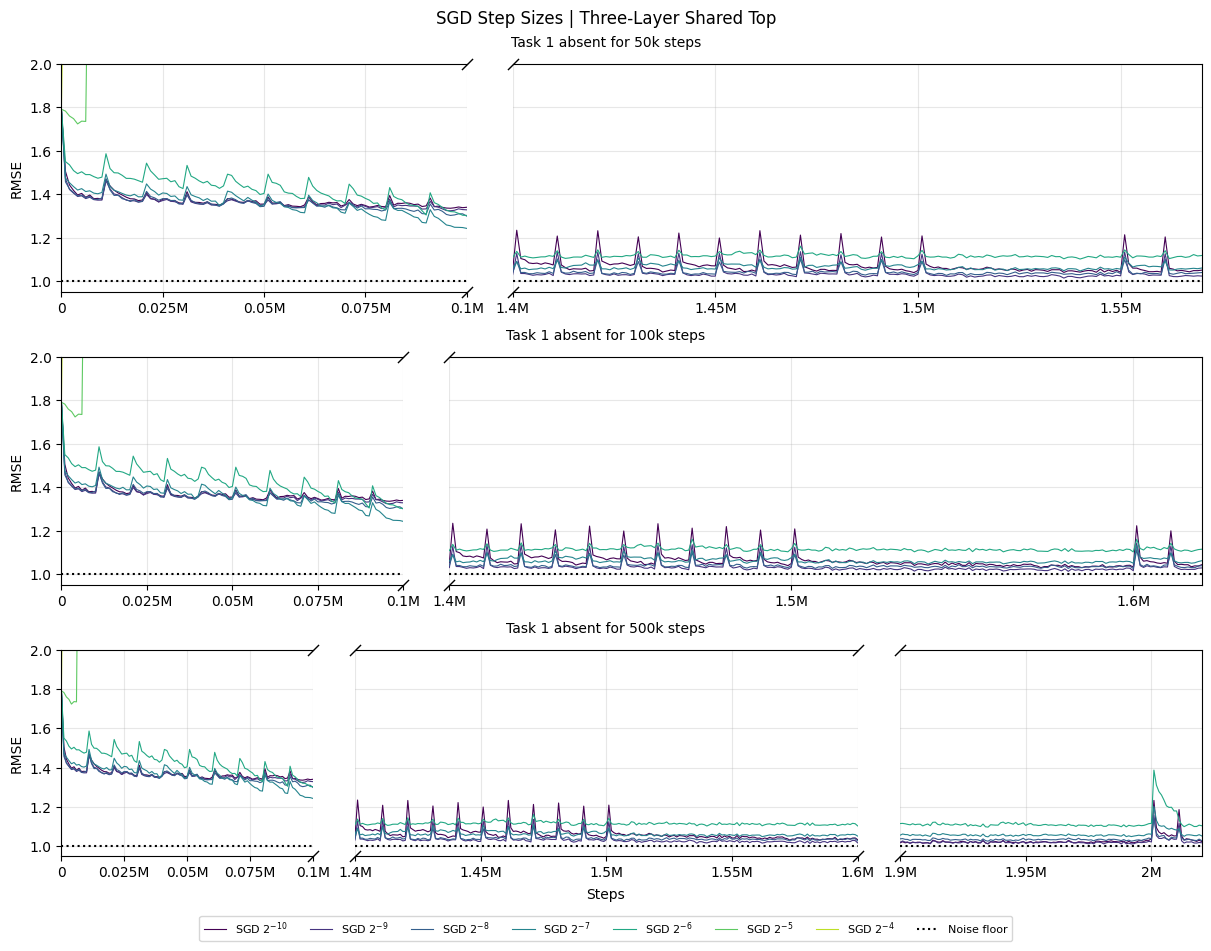

Runtime: 40.0s
Unstandardized SGD final-20k RMSE: 2^-10: 1.233, 2^-9: 1.110, 2^-8: 1.091, 2^-7: 1.082, 2^-6: 1.102, 2^-5: 1.124, 2^-4: 1.208
Unstandardized SGD chosen step size: 2^-7


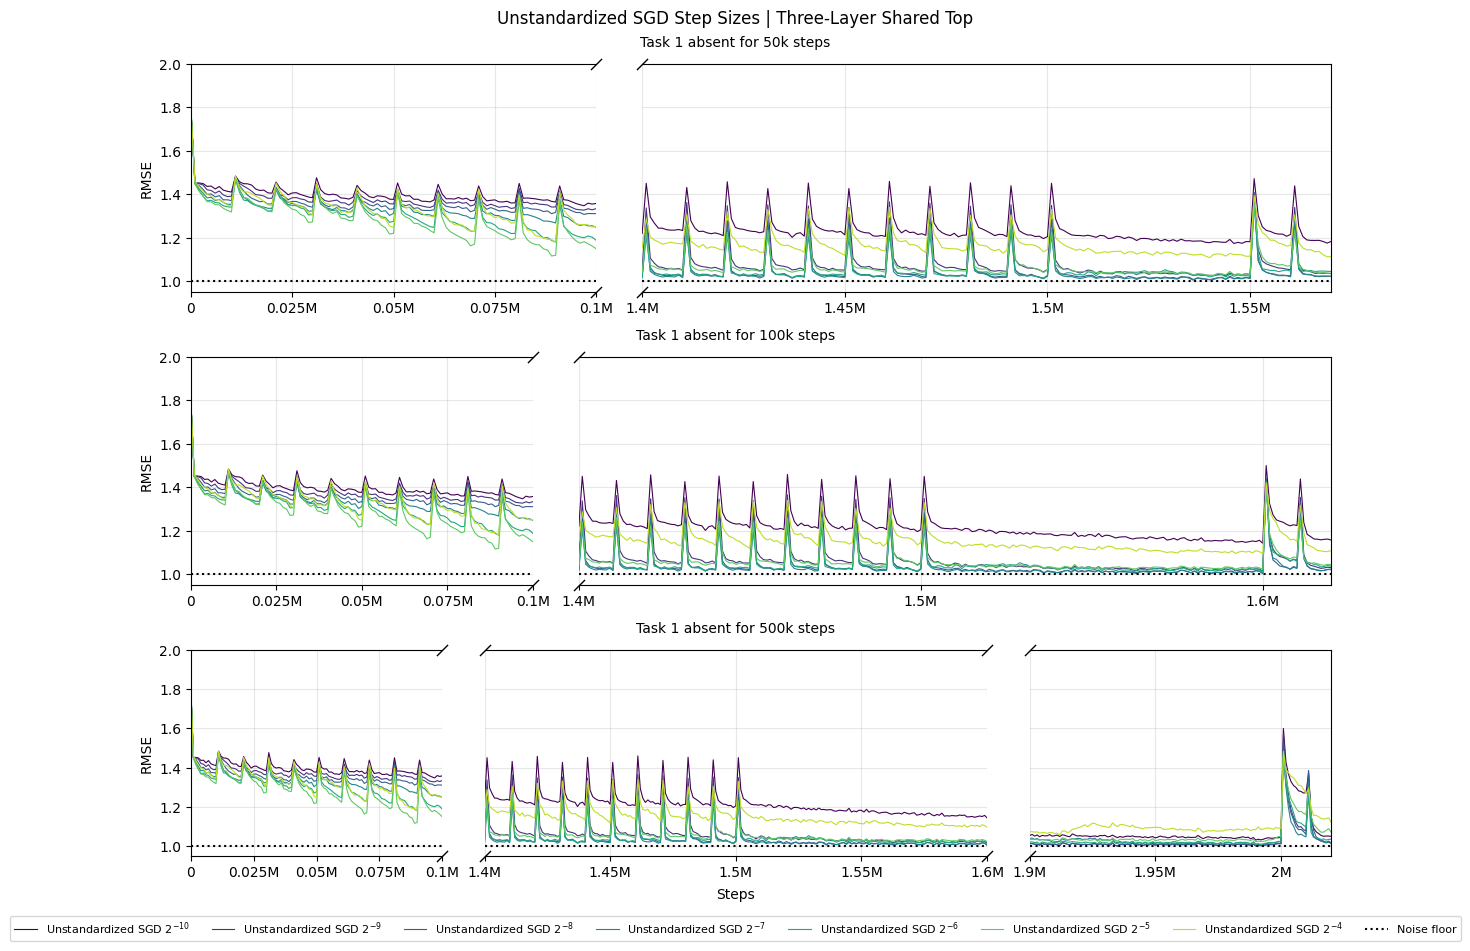

In [6]:
rates = 2. ** np.array(SGD_EXPONENTS)
tile = lambda a: jnp.tile(a, (len(rates),) + (1,) * (a.ndim - 1))  # lane = rate index * N_SEEDS + seed
learners = jax.vmap(partial(init_learner, autostep=False))(learner_keys)


def sweep(step, label):
    curves = run_all(step, (jax.tree.map(tile, learners), jnp.repeat(rates, N_SEEDS)), tile(data_keys), jax.tree.map(tile, teachers))
    curves = [curve.reshape(len(rates), N_SEEDS, -1) for curve in curves]
    final = np.mean([curve[:, :, -2 * PERIOD // WINDOW:].mean(axis=(1, 2)) for curve in curves], axis=0)
    best = int(np.argmin(np.where(np.isfinite(final), final, np.inf)))
    print(f'{label} final-20k RMSE:', ', '.join(f'2^{p}: {v:.3f}' for p, v in zip(SGD_EXPONENTS, final)))
    print(f'{label} chosen step size: 2^{SGD_EXPONENTS[best]}')
    plot_runs(curves, [f'{label} $2^{{{p}}}$' for p in SGD_EXPONENTS], plt.cm.viridis(np.linspace(0, .9, len(rates))),
              f'{label} Step Sizes | Three-Layer Shared Top')
    return curves, best


sgd, best = sweep(sgd_step, 'SGD')
plain_sgd, plain_best = sweep(partial(sgd_step, standardized=False), 'Unstandardized SGD')

## SGD, Autostep and baselines

The two SGD curves are the chosen sweep curves, not new runs. Autostep and both baselines see the same inputs and noise.

Runtime: 87.6s


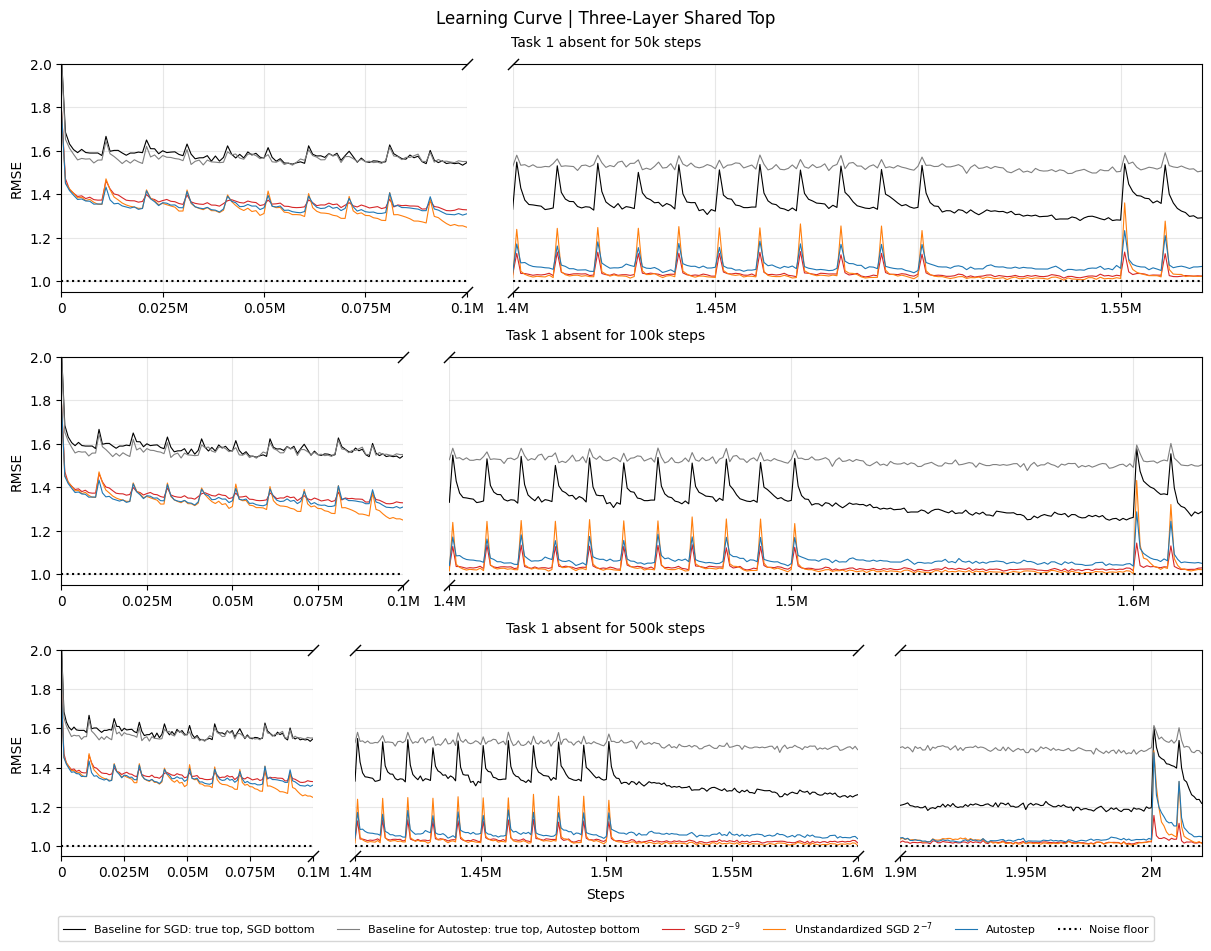

In [7]:
def autostep_and_baselines(state, x, y, teacher):
    learner, sgd_baseline, autostep_baseline = state
    learner, autostep_error = autostep_step(learner, x, y, teacher)
    sgd_baseline, sgd_baseline_error = sgd_baseline_step(sgd_baseline, x, y, teacher)
    autostep_baseline, autostep_baseline_error = autostep_baseline_step(autostep_baseline, x, y, teacher)
    return (learner, sgd_baseline, autostep_baseline), jnp.stack([autostep_error, sgd_baseline_error, autostep_baseline_error])


states = (jax.vmap(partial(init_learner, autostep=True))(learner_keys),
          (jax.vmap(partial(init_baseline, autostep=False))(learner_keys), jnp.full(N_SEEDS, rates[best])),
          jax.vmap(partial(init_baseline, autostep=True))(learner_keys))
autostep, sgd_baseline, autostep_baseline = zip(*[np.moveaxis(curve, -1, 0) for curve in
                                                  run_all(autostep_and_baselines, states, data_keys, teachers)])
plot_runs([np.stack([sb, ab, s[best], p[plain_best], a]) for s, p, a, sb, ab in zip(sgd, plain_sgd, autostep, sgd_baseline, autostep_baseline)],
          ['Baseline for SGD: true top, SGD bottom', 'Baseline for Autostep: true top, Autostep bottom',
           f'SGD $2^{{{SGD_EXPONENTS[best]}}}$', f'Unstandardized SGD $2^{{{SGD_EXPONENTS[plain_best]}}}$', 'Autostep'],
          ['black', 'gray', 'tab:red', 'tab:orange', 'tab:blue'], 'Learning Curve | Three-Layer Shared Top')

## Feature change during the absence

Rerun SGD (chosen step size) and Autostep with the same seeds and data, snapshotting both every 10k steps through the 500k absence. Units are measured on 1000 fixed random inputs.
- **Layer 1, task 1's units:** when task 1 leaves, each first-layer unit is assigned to the task of the teacher first-layer LTU whose firing it best matches (largest |correlation|); units assigned to task 1 are kept.
- **Layer 3, all units:** the shared top. Its firing on raw inputs changes whenever layer 2 is relearned, so each third-layer unit is measured on fixed inputs to that layer: the standardized second-layer activations on the probe inputs when task 1 left.

Units firing on fewer than 1% or more than 99% of the inputs at that time are left out. The curves are medians over units and seeds of each unit's |correlation| with its own firing when task 1 left.

Runtime: 73.3s


SGD layer-1 units kept per seed: [21 27 18 20 23]
Autostep layer-1 units kept per seed: [21 21 22 21 26]


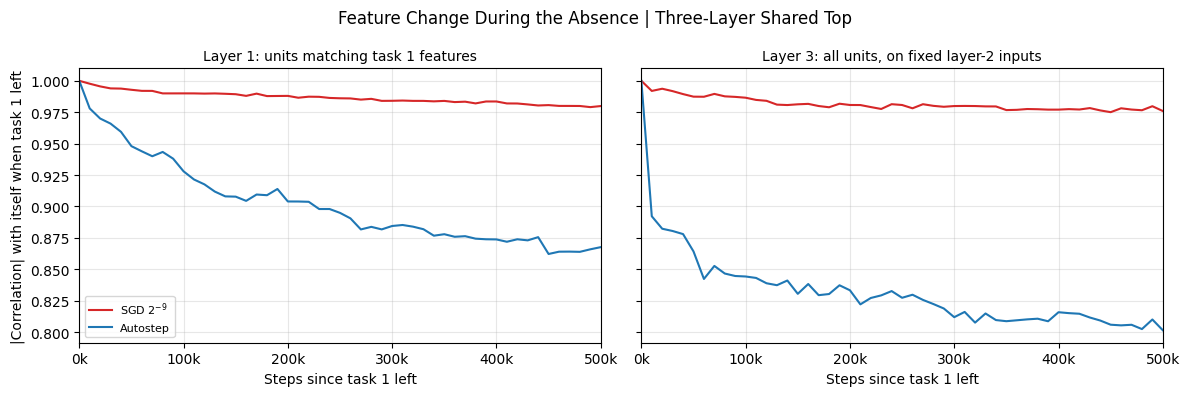

In [8]:
PROBE = jax.random.rademacher(jax.random.PRNGKey(2), (1000, N_INPUTS), dtype=jnp.float32)
SNAPSHOT = 10_000


def sgd_and_autostep(state, x, y, teacher):
    sgd_state, learner = state
    sgd_state, sgd_error = sgd_step(sgd_state, x, y, teacher)
    learner, autostep_error = autostep_step(learner, x, y, teacher)
    return (sgd_state, learner), jnp.stack([sgd_error, autostep_error])


def activity(weights, means, inputs):
    """Per hidden layer: firing (input, unit) and standardized activation."""
    a, bits, activations = inputs, [], []
    for w, mean in zip(weights[:-1], means):
        b = (a @ w[:, :-1].T + w[:, -1] > 0).astype(jnp.float32)
        a = (b - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))
        bits.append(b); activations.append(a)
    return bits, activations


def zscore(a):  # over inputs, axis -2
    return (a - a.mean(-2, keepdims=True)) / (a.std(-2, keepdims=True) + 1e-8)


started = perf_counter()
simulate = jax.jit(jax.vmap(partial(run, sgd_and_autostep), in_axes=(0, 0, 0, None)))
states = ((jax.vmap(partial(init_learner, autostep=False))(learner_keys), jnp.full(N_SEEDS, rates[best])),
          jax.vmap(partial(init_learner, autostep=True))(learner_keys))
states, keys, _, _ = simulate(states, data_keys, teachers, ACQUISITION_TASKS)
snapshots = [[(l.weights, l.means) for l in (states[0][0], states[1])]]
for _ in range(ABSENCES[-1] // SNAPSHOT):  # task 0 only; task 1 is absent
    states, keys, _, _ = simulate(states, keys, teachers, np.zeros(SNAPSHOT // WINDOW, int))
    snapshots.append([(l.weights, l.means) for l in (states[0][0], states[1])])
print(f'Runtime: {perf_counter() - started:.1f}s')

teacher_first = zscore((jnp.einsum('pi,sli->spl', PROBE, teachers[0].reshape(N_SEEDS, -1, N_INPUTS)) > 2).astype(jnp.float32))
activity_all = jax.jit(jax.vmap(activity, in_axes=(0, 0, None)))
top_firing = jax.jit(jax.vmap(lambda w, a: (a @ w[:, :-1].T + w[:, -1] > 0).astype(jnp.float32)))
medians = {}
for method in range(2):
    start_bits, start_activations = activity_all(*snapshots[0][method], PROBE)
    first = np.stack([np.asarray(activity_all(*s[method], PROBE)[0][0]) for s in snapshots])  # (snapshot, seed, input, unit)
    top = np.stack([np.asarray(top_firing(s[method][0][2], start_activations[1])) for s in snapshots])
    for layer, firing in ((1, first), (3, top)):
        start = zscore(firing[0])
        correlation = np.abs(np.einsum('tspu,spu->tsu', zscore(firing), start)) / len(PROBE)
        rate = firing[0].mean(1)
        keep = (rate >= .01) & (rate <= .99)
        if layer == 1:
            keep &= np.abs(np.einsum('spu,spl->sul', start, teacher_first)).argmax(-1) // WIDTH == 1
            print(['SGD', 'Autostep'][method], 'layer-1 units kept per seed:', keep.sum(1))
        medians[method, layer] = np.median(correlation[:, keep], axis=1)

steps = np.arange(len(snapshots)) * SNAPSHOT
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, layer, title in zip(axes, (1, 3), ('Layer 1: units matching task 1 features', 'Layer 3: all units, on fixed layer-2 inputs')):
    for method, (label, color) in enumerate(((f'SGD $2^{{{SGD_EXPONENTS[best]}}}$', 'tab:red'), ('Autostep', 'tab:blue'))):
        ax.plot(steps, medians[method, layer], label=label, color=color)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, steps[-1])
    ax.xaxis.set_major_formatter(lambda v, _: f'{v / 1000:g}k')
    ax.set_xlabel('Steps since task 1 left')
    ax.grid(True, alpha=.3)
axes[0].set_ylabel('|Correlation| with itself when task 1 left')
axes[0].legend(fontsize=8)
fig.suptitle('Feature Change During the Absence | Three-Layer Shared Top')
fig.tight_layout()
plt.show()